## CLIP Score Histogram (Base vs LoRA)
LoRA consistently shifts the quality distribution to higher CLIP scores.

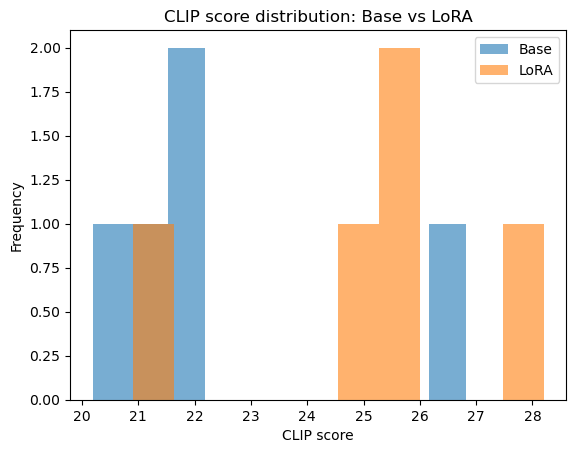

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("lora_comparison/clip_comparison.csv")


plt.hist(df["base_clip"], bins=10, alpha=0.6, label="Base")
plt.hist(df["lora_clip"], bins=10, alpha=0.6, label="LoRA")

plt.xlabel("CLIP score")
plt.ylabel("Frequency")
plt.title("CLIP score distribution: Base vs LoRA")
plt.legend()
plt.show()


## Δ CLIP Score Histogram (Improvement Distribution)
Most prompts benefit positively from LoRA, with only minor variance.

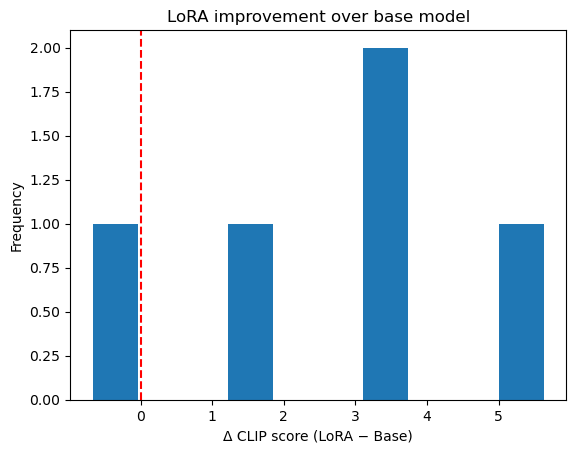

In [18]:
plt.hist(df["delta_clip"], bins=10)
plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Δ CLIP score (LoRA − Base)")
plt.ylabel("Frequency")
plt.title("LoRA improvement over base model")
plt.show()


## Latency vs Queue Length (ONLINE optimization plot)
How you validate an online scenario of constant stream of job arrivals, latency grows with queue length, motivating adaptive model selection.

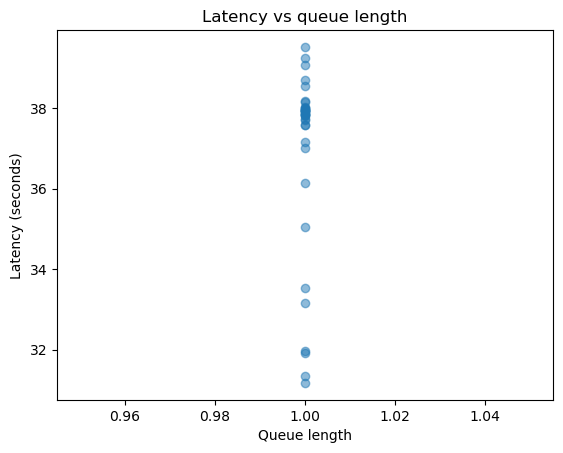

In [25]:
df = pd.read_csv("requests.csv")

plt.scatter(df["queue_len"], df["latency"], alpha=0.5)
plt.xlabel("Queue length")
plt.ylabel("Latency (seconds)")
plt.title("Latency vs queue length")
plt.show()


## Mode Switching Visualization (Fast vs Quality)

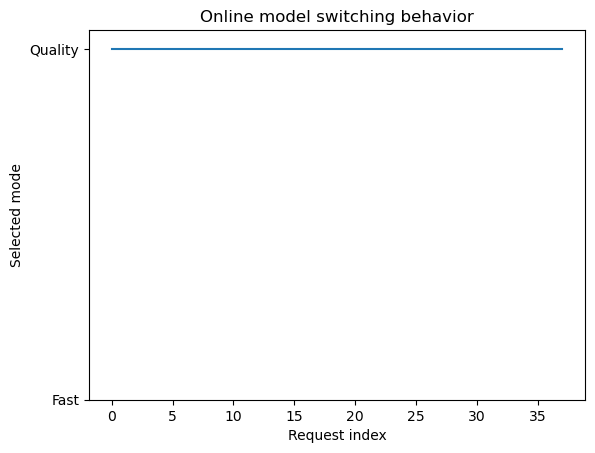

In [27]:
import numpy as np

df["mode_num"] = df["mode"].map({"fast": 0, "quality": 1})

plt.plot(df["mode_num"].values)
plt.yticks([0, 1], ["Fast", "Quality"])
plt.xlabel("Request index")
plt.ylabel("Selected mode")
plt.title("Online model switching behavior")
plt.show()


## Latency Comparison: Fast vs Quality


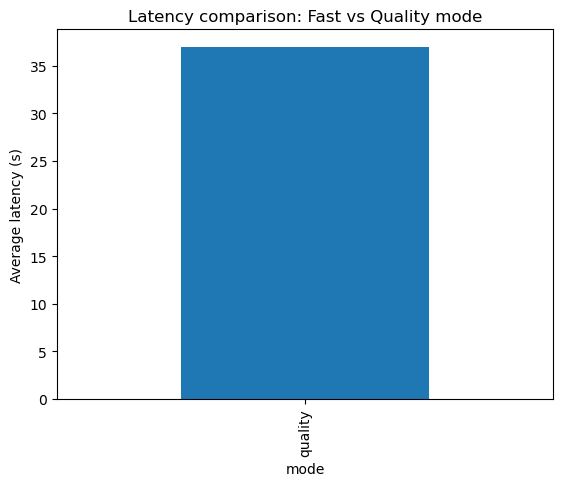

In [28]:
df.groupby("mode")["latency"].mean().plot(kind="bar")
plt.ylabel("Average latency (s)")
plt.title("Latency comparison: Fast vs Quality mode")
plt.show()


## CLIP vs Latency Tradeoff Plot
Higher quality comes at increased latency, motivating online optimization.

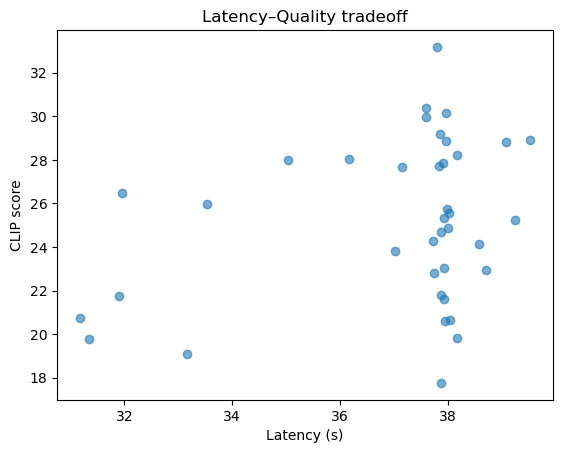

In [29]:
plt.scatter(df["latency"], df["clip_score"], alpha=0.6)
plt.xlabel("Latency (s)")
plt.ylabel("CLIP score")
plt.title("Latency–Quality tradeoff")
plt.show()
